# Load and stored VS and bogus cutouts

This notebook is the final notebook related to get, saved, and load cutouts:

* Master file with a list of all vs and bogus queried from ALeRCE were obtained in `0.alerce_get_vsandbogus_objs.ipynb` and SN in `01.alerce_get_sn_objs.ipynb`. (No reason why sn is in a different file)
```
path_save = "/content/drive/MyDrive/hackathon_colombia_oct_2026"
df_vsbogus = pd.read_csv(os.path.join(path_save,'alerce_vs_bogus_classifier2_probgt08.csv.gz'))
df_sn = pd.read_csv(os.path.join(path_save,'alerce_sn_classifier2_probgt08.csv.gz'))
```

* The cutouts are in zip files. VS and SN are in a single .zip file, bogus are divided in two .zip files. The cutouts were saved using Fink, and not ALeRCE
  - The notebook `2fink_save_stamps.ipynb` shows how to do it on google drive, but, if you want to save many images, I recomend to use a python script and run it in your computer or any computer.
  - `save_bogus_stamps.py`, that is the same as the notebook, but with the script I was able to save the cutouts directly on my computer and let it run overnight. Once all stamps are saved compress all the images.
  There is a folder for each type of object `vs_zip`, `bogus_zip` and `sn_zip`
```
path_save = "/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26"
zip_paths = glob.glob(path_save+'/*zip/*zip') # the zip file with the cutouts
```


* I created a pickle file where the path to the cutouts, in .npy format, is sorted by object id and following the diff, sci, tmpl order. This is the file, with the .zip path that I used to read the cutouts. NO NEED TO EXPAND THE ZIP FILES. The pickel files were created in `3create_file_from_zip_file.ipynb`.
```
path_save = "/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26"
file_list_path = glob.glob(path_save+'/*zip/file_list*') #the file list has the cutouts ordered by objectid, and as diff, sci, tmpl
```

* The light curves and forced light curves are also in zip files.
  - `save_lc_fp.py`: python script used to save the light curves and the forced photometry
```
path_save_lc = "/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_lc_oct_26"
zip_path_lc = glob.glob(path_save_lc+'/*.zip')

path_save_fplc = "/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_fp_lc_oct_26"
zip_path_fplc = glob.glob(path_save_fplc+'/*.zip')
```

## This notebooks reads the zip files and the pickle files, load the .npy files for cutouts, and .csv.gz for light curves and forced light curves. For each case create an dictionary, where the key is the objectId. There is one dict for VS for bogus and for sn


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import time
import threading
from concurrent.futures import ThreadPoolExecutor
import glob
import io
import zipfile
import pickle

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# path_save = "/content/drive/MyDrive/notebook_hack_colombia"
# df_all = pd.read_csv(os.path.join(path_save,'alerce_vs_bogus_classifier2_probgt08.csv.gz'))

In [ ]:
path_save = "/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26"

In [ ]:
path_save+'/*zip'

'/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/*zip'

In [ ]:
glob.glob(path_save+'/*zip/file_list*')

['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/vs_zip/file_list_vs_cutouts.pkl',
 '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/bogus_zip/file_list_bogus_cutouts_1.pkl',
 '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/bogus_zip/file_list_bogus_cutouts_2.pkl',
 '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/sn_zip/file_list_sn_cutouts.pkl']

In [ ]:
file_list_path = glob.glob(path_save+'/*zip/file_list*') #the file list has the cutouts ordered by objectid, and as diff, sci, tmpl

In [ ]:
zip_paths = glob.glob(path_save+'/*zip/*zip') # the zip file with the cutouts

In [ ]:
zip_paths

['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/vs_zip/VS_cutouts.zip',
 '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/bogus_zip/bogus_cutouts_1.zip',
 '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/bogus_zip/bogus_cutouts_2.zip',
 '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/sn_zip/sn_cutouts.zip']

# Get VS cutouts

In [ ]:
def save_cutouts(file_list_path, zip_paths):

  all_vs_arrays = dict()
  for pick_path, zip_path in zip(file_list_path, zip_paths):
    with zipfile.ZipFile(zip_path, 'r') as zipper:
      with open(pick_path, 'rb') as file:
        objs_path = pickle.load(file)
        for obj_path in objs_path:
          objid = obj_path[0].split('/')[-2]
          all_vs_arrays[str(objid)] = [None, None, None]

          for ix, file_name in enumerate(obj_path):

            if file_name.endswith('.npy'):

                with zipper.open(file_name, mode='r') as file_stream:
                  buffered_stream = io.BufferedReader(file_stream)
                  array_data = np.load(buffered_stream)

                  all_vs_arrays[str(objid)][ix] = array_data

  return all_vs_arrays

In [ ]:
print(file_list_path[0:1], zip_paths[0:1])

['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/vs_zip/file_list_vs_cutouts.pkl'] ['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/vs_zip/VS_cutouts.zip']


In [ ]:
all_vs_arrays = save_cutouts(file_list_path[0:1], zip_paths[0:1])

In [ ]:
objids_available_vs = list(all_vs_arrays.keys())

In [ ]:
len(objids_available_vs)

21677

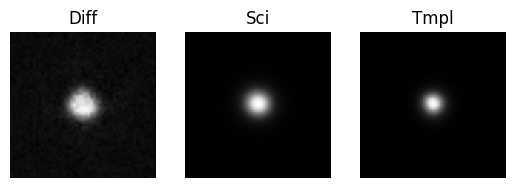

In [ ]:
fig, ax = plt.subplots(1,3)
for (ix, axes), n in zip(enumerate(ax), ['Diff', 'Sci', 'Tmpl']):
  axes.imshow(all_vs_arrays[objids_available_vs[-2]][ix], cmap='Greys_r')
  axes.set_title(n)
  axes.axis('off')

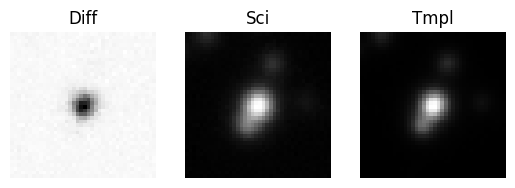

In [ ]:
fig, ax = plt.subplots(1,3)
for (ix, axes), n in zip(enumerate(ax), ['Diff', 'Sci', 'Tmpl']):
  axes.imshow(all_vs_arrays[objids_available_vs[7815]][ix], cmap='Greys_r')
  axes.set_title(n)
  axes.axis('off')

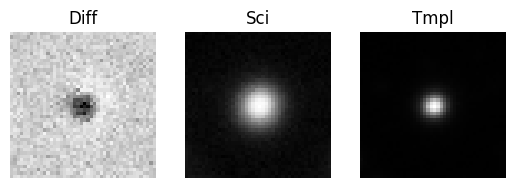

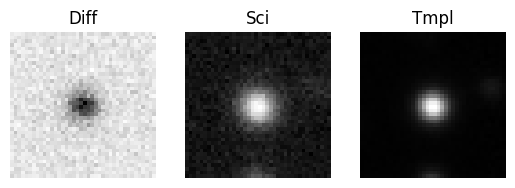

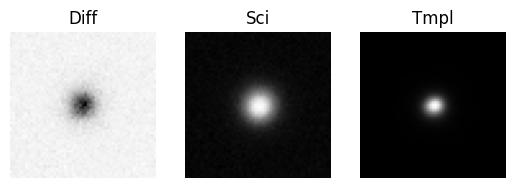

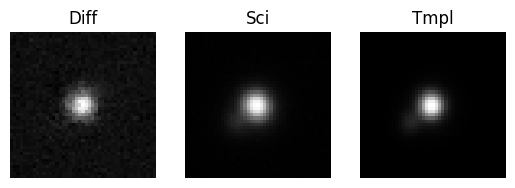

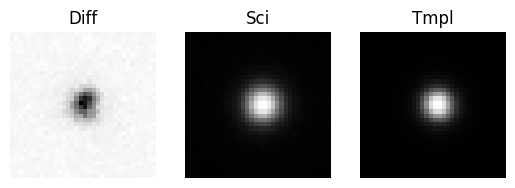

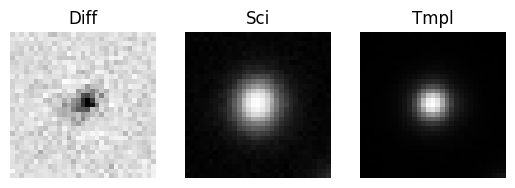

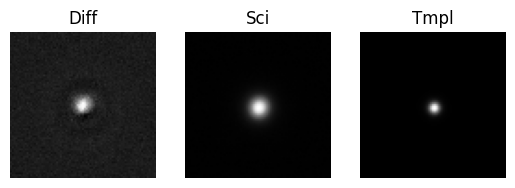

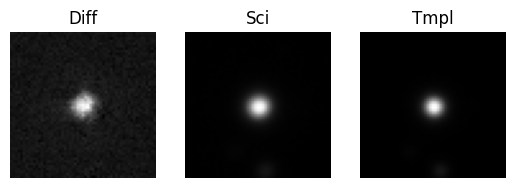

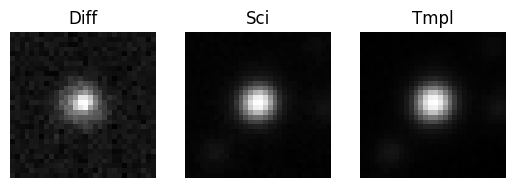

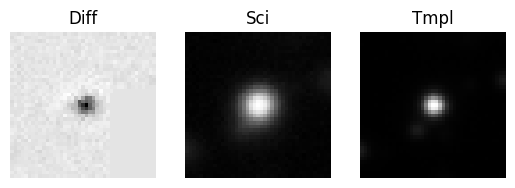

In [ ]:
for iyi in np.random.choice(objids_available_vs, size=10):
  fig, ax = plt.subplots(1,3)
  for (ix, axes), n in zip(enumerate(ax), ['Diff', 'Sci', 'Tmpl']):
    axes.imshow(all_vs_arrays[iyi][ix], cmap='Greys_r')
    axes.set_title(n)
    axes.axis('off')

# Get bogus cutouts

In [ ]:
print(file_list_path[1:-1], zip_paths[1:-1])

['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/bogus_zip/file_list_bogus_cutouts_1.pkl', '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/bogus_zip/file_list_bogus_cutouts_2.pkl'] ['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/bogus_zip/bogus_cutouts_1.zip', '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/bogus_zip/bogus_cutouts_2.zip']


In [ ]:
all_bogus_arrays = save_cutouts(file_list_path[1:-1], zip_paths[1:-1])

In [ ]:
objids_available_bogus = list(all_bogus_arrays.keys())

In [ ]:
len(objids_available_bogus)

21319

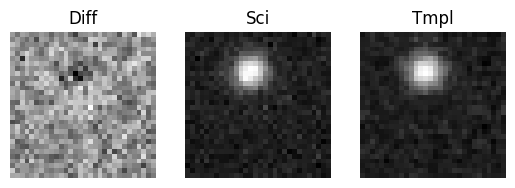

In [ ]:
fig, ax = plt.subplots(1,3)
for (ix, axes), n in zip(enumerate(ax), ['Diff', 'Sci', 'Tmpl']):
  axes.imshow(all_bogus_arrays[objids_available_bogus[0]][ix], cmap='Greys_r')
  axes.set_title(n)
  axes.axis('off')

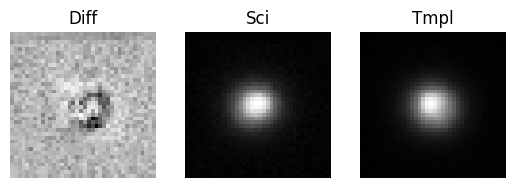

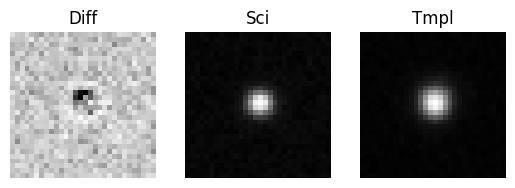

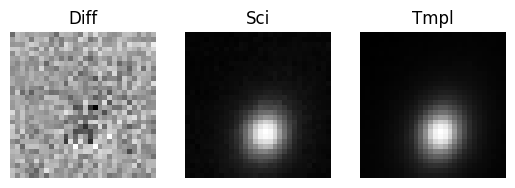

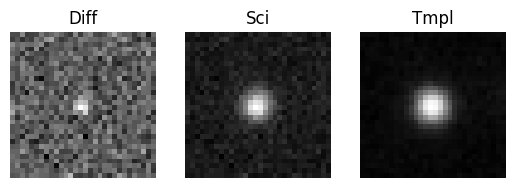

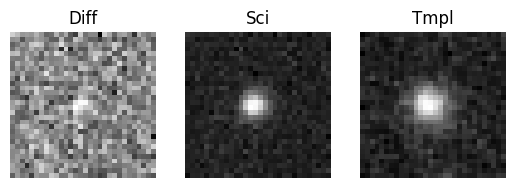

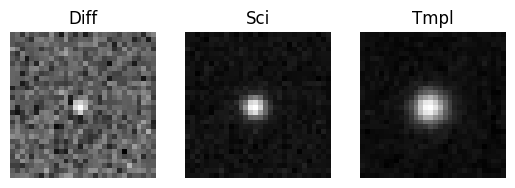

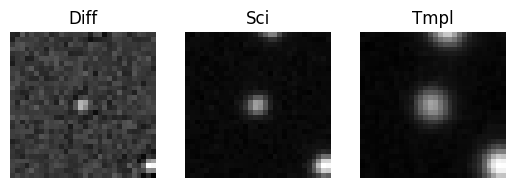

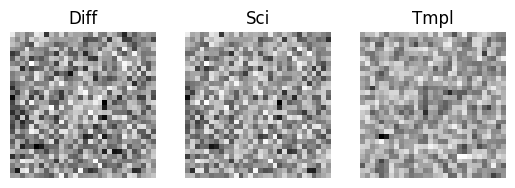

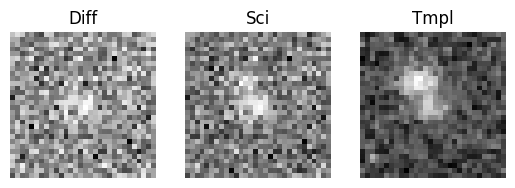

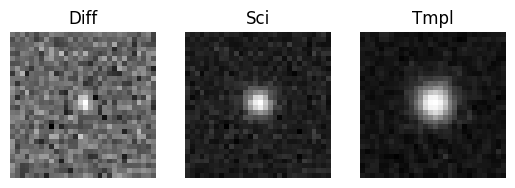

In [ ]:
for iyi in np.random.choice(objids_available_bogus, size=10):
  fig, ax = plt.subplots(1,3)
  for (ix, axes), n in zip(enumerate(ax), ['Diff', 'Sci', 'Tmpl']):
    axes.imshow(all_bogus_arrays[iyi][ix], cmap='Greys_r')
    axes.set_title(n)
    axes.axis('off')

# Get SN cutouts

In [ ]:
print(file_list_path[-1:], zip_paths[-1:])

['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/sn_zip/file_list_sn_cutouts.pkl'] ['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/sn_zip/sn_cutouts.zip']


In [ ]:
all_sn_arrays = save_cutouts(file_list_path[-1:], zip_paths[-1:])

In [ ]:
objids_available_sn = list(all_sn_arrays.keys())
len(objids_available_sn)

6514

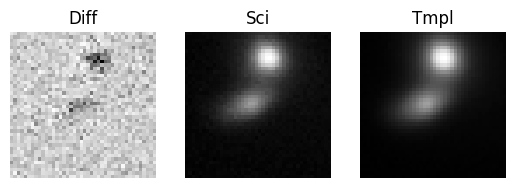

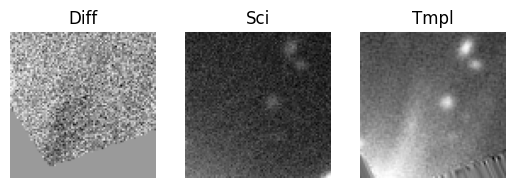

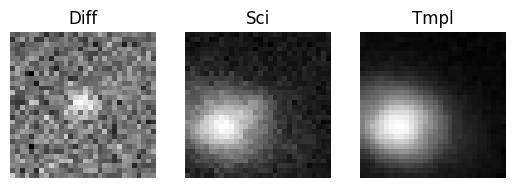

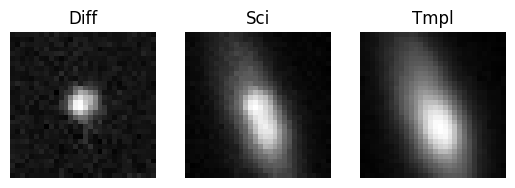

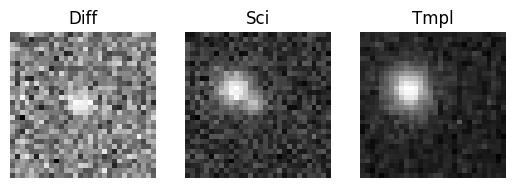

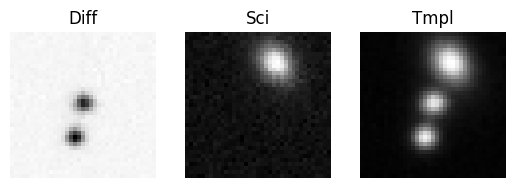

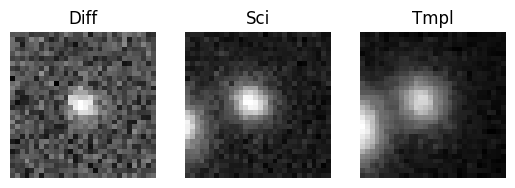

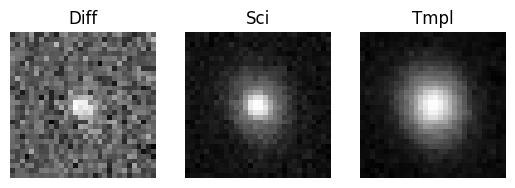

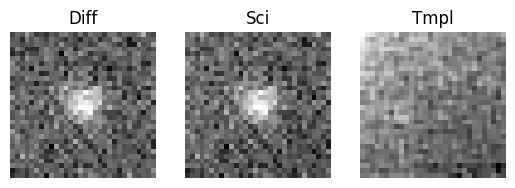

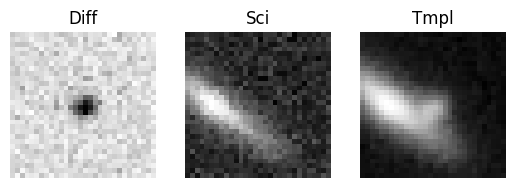

In [ ]:
for iyi in np.random.choice(objids_available_sn, size=10):
  fig, ax = plt.subplots(1,3)
  for (ix, axes), n in zip(enumerate(ax), ['Diff', 'Sci', 'Tmpl']):
    axes.imshow(all_sn_arrays[iyi][ix], cmap='Greys_r')
    axes.set_title(n)
    axes.axis('off')

#Get light curves

In [ ]:
path_save_lc = "/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_lc_oct_26"

In [ ]:
zip_paths_lc = glob.glob(path_save_lc+'/*zip')
zip_paths_lc

['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_lc_oct_26/bogus.zip',
 '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_lc_oct_26/sn.zip',
 '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_lc_oct_26/vs.zip']

In [ ]:
filter_colors = {
    "u": "#1600ea",
    "g": "#49be61",
    "r": "#c61c00",
    "i": "#ffc200",
    "z": "#f341a2",
    "y": "#5d0000",
}

In [ ]:
import astropy.units as u

In [ ]:
def add_prv_mag(flux, flux_err):
    """Convert flux (nJy) to AB magnitude (asymmetric error from flux ± fluxErr)"""
    if flux[0] < 0:
      return flux, flux_err
    else:
      flux = np.asarray(flux, dtype="float64")
      flux_err = np.asarray(flux_err, dtype="float64")
      mag = u.nJy.to(u.ABmag, flux)
      upper = u.nJy.to(u.ABmag, flux + flux_err)
      lower = u.nJy.to(u.ABmag, flux - flux_err)
      mag_err = -(upper - lower) / 2
      return mag, mag_err

In [ ]:
# file_list_total = []
# observations = dict()
# for pick_path, zip_path in zip(file_list_path[1:2], zip_paths_lc[1:2]):
#   with zipfile.ZipFile(zip_path, 'r') as zipper:
#       # List all files inside the zip
#       for file_name in zipper.namelist():
#         print(file_name)
#         if file_name.endswith('.npy'):
#           obs_num = file_name.split("/")[-2]
#           observations.setdefault(obs_num, []).append(file_name)
#   for i, (k, v) in enumerate(observations.items()):
#       file_list_total.append(sorted(v))

In [ ]:
file_list_path

['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/vs_zip/file_list_vs_cutouts.pkl',
 '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/bogus_zip/file_list_bogus_cutouts_1.pkl',
 '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/bogus_zip/file_list_bogus_cutouts_2.pkl',
 '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/sn_zip/file_list_sn_cutouts.pkl']

In [ ]:
def save_lc(file_list_path, zip_paths_lc):

  all_lc_sn_arrays = dict()
  for pick_path, zip_path in zip(file_list_path, zip_paths_lc):
    type_name = zip_path.split('/')[-1].split('.')[0] # sn/vs/bogus
    with zipfile.ZipFile(zip_path, 'r') as zipper:
      with open(pick_path, 'rb') as file:
        objs_path = pickle.load(file)
        for obj_path in objs_path:
          objid = obj_path[0].split('/')[-2]
          file_name = f"{type_name}/{objid}/{objid}_lc.csv.gz"
          try:

            with zipper.open(file_name, mode='r') as file_stream:
              buffered_stream = io.BufferedReader(file_stream)
              array_data = pd.read_csv(buffered_stream, compression="gzip")
              all_lc_sn_arrays[str(objid)] = array_data
          except Exception as e:
            print(f"{e} for {objid}")

  return all_lc_sn_arrays

## Get VS light curves

In [ ]:
file_list_path[0:1], zip_paths_lc[-1:]

(['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/vs_zip/file_list_vs_cutouts.pkl'],
 ['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_lc_oct_26/vs.zip'])

In [ ]:
all_lc_vs_arrays = save_lc(file_list_path[0:1], zip_paths_lc[-1:])

"There is no item named 'vs/170507920794452012/170507920794452012_lc.csv.gz' in the archive" for 170507920794452012
"There is no item named 'vs/170631094993420692/170631094993420692_lc.csv.gz' in the archive" for 170631094993420692
"There is no item named 'vs/170455187036046534/170455187036046534_lc.csv.gz' in the archive" for 170455187036046534
"There is no item named 'vs/170437564114141462/170437564114141462_lc.csv.gz' in the archive" for 170437564114141462
"There is no item named 'vs/170455188113981823/170455188113981823_lc.csv.gz' in the archive" for 170455188113981823
"There is no item named 'vs/170437563628126621/170437563628126621_lc.csv.gz' in the archive" for 170437563628126621
"There is no item named 'vs/170028515507306554/170028515507306554_lc.csv.gz' in the archive" for 170028515507306554
"There is no item named 'vs/170455188275986530/170455188275986530_lc.csv.gz' in the archive" for 170455188275986530
"There is no item named 'vs/170631029182169178/170631029182169178_lc.csv

In [ ]:
objids_available_lcvs = list(all_lc_vs_arrays.keys())

In [ ]:
len(objids_available_lcvs)

21468

/usr/local/lib/python3.13/dist-packages/astropy/units/function/logarithmic.py:67: RuntimeWarning: invalid value encountered in log10
  return dex.to(self._function_unit, np.log10(x))
/usr/local/lib/python3.13/dist-packages/astropy/units/function/logarithmic.py:67: RuntimeWarning: invalid value encountered in log10
  return dex.to(self._function_unit, np.log10(x))


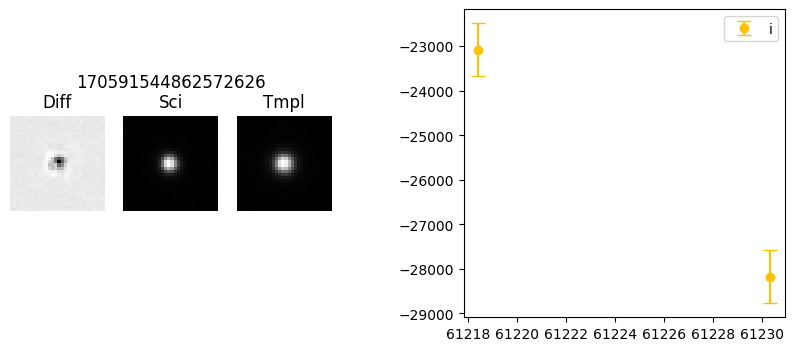

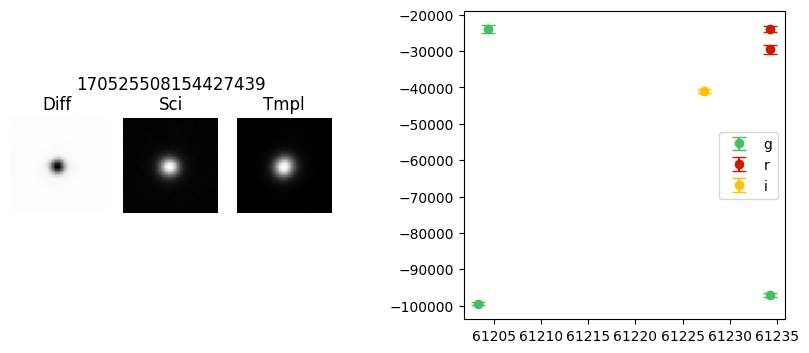

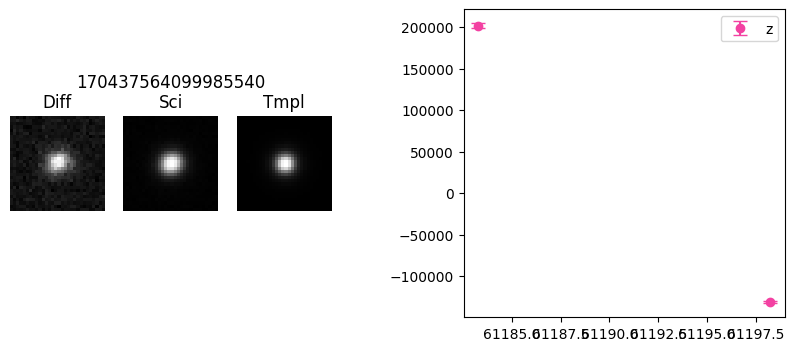

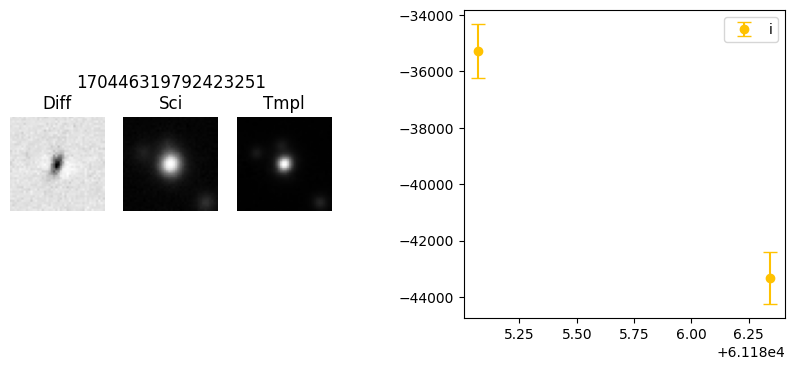

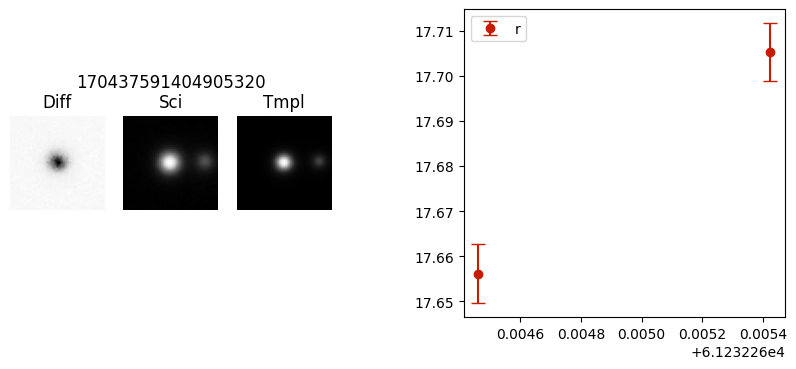

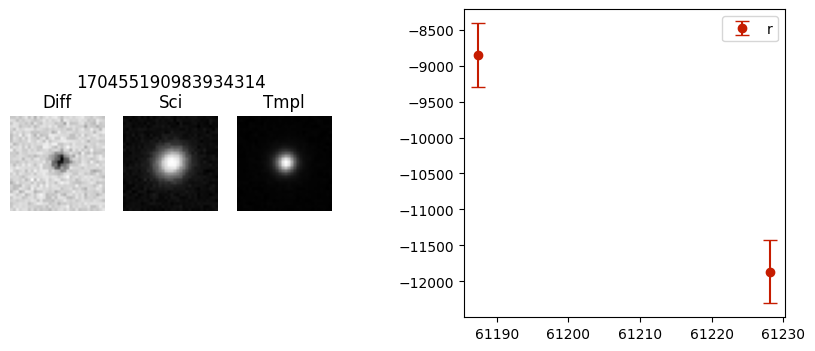

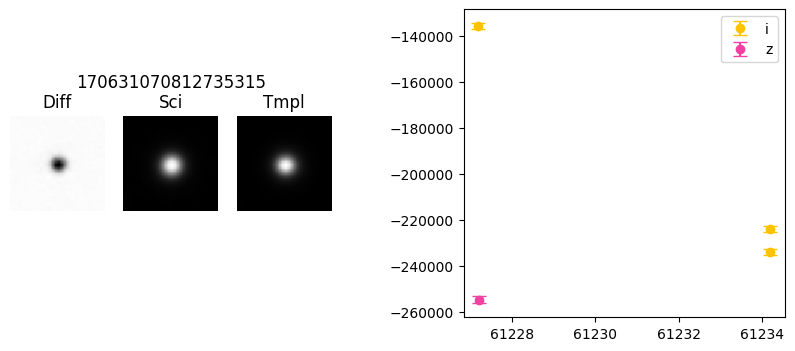

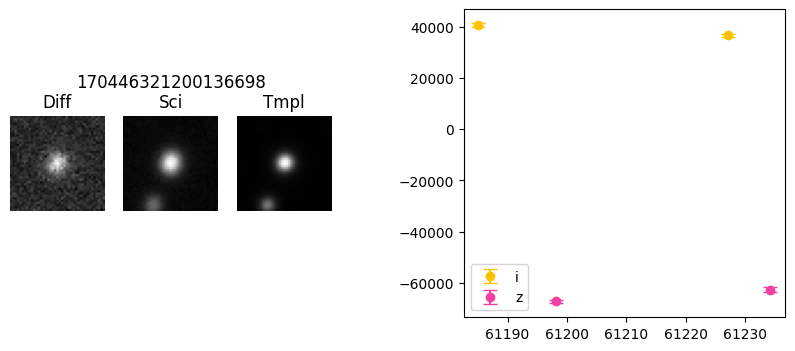

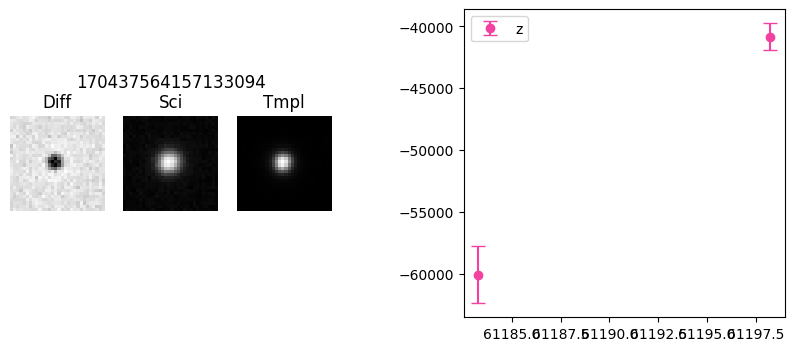

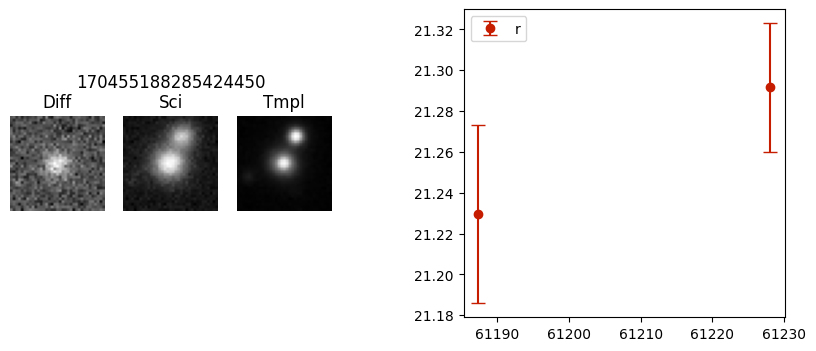

In [ ]:
np.random.seed(565)
for iyi in np.random.choice(objids_available_vs, size=10):
  fig, ax = plt.subplot_mosaic('0123444', figsize=(10, 4))
  for ix, n in zip(ax, ['Diff', f'{iyi}\nSci', 'Tmpl']):
    if int(ix) < 3:
      ax[ix].imshow(all_vs_arrays[iyi][int(ix)], cmap='Greys_r')
      ax[ix].set_title(n)
      ax[ix].axis('off')
    else:
      pass
  ax['3'].axis('off')
  try:
    light_curve_df = all_lc_vs_arrays[iyi.item()]
    for coloru in filter_colors:

      light_curve_df['r:psfMag'], light_curve_df['r:psfMagErr'] = add_prv_mag(light_curve_df['r:psfFlux'], light_curve_df['r:psfFluxErr'])

      df = light_curve_df[light_curve_df["r:band"] == coloru]
      if len(df) > 0:
        scatt = ax['4'].errorbar(df['r:midpointMjdTai'],df['r:psfMag'], yerr=df['r:psfMagErr'],
                        color=filter_colors[coloru],  fmt='o', capsize=5,
                        label=coloru)

  except Exception as e:
    print(e)
    scatt = ax['4'].scatter(0,0,label='No lc')
  plt.legend()

## Get bogus light curves

In [ ]:
file_list_path[1:-1], zip_paths_lc[0:1]

(['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/bogus_zip/file_list_bogus_cutouts_1.pkl',
  '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/bogus_zip/file_list_bogus_cutouts_2.pkl'],
 ['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_lc_oct_26/bogus.zip'])

In [ ]:
all_lc_bogus_arrays = save_lc(file_list_path[1:-1], [zip_paths_lc[0:1][0],zip_paths_lc[0:1][0]])

"There is no item named 'bogus/170591528103182784/170591528103182784_lc.csv.gz' in the archive" for 170591528103182784
"There is no item named 'bogus/314007345740382264/314007345740382264_lc.csv.gz' in the archive" for 314007345740382264
"There is no item named 'bogus/170587110482903216/170587110482903216_lc.csv.gz' in the archive" for 170587110482903216
"There is no item named 'bogus/170631098003358431/170631098003358431_lc.csv.gz' in the archive" for 170631098003358431
"There is no item named 'bogus/170591514130907311/170591514130907311_lc.csv.gz' in the archive" for 170591514130907311
"There is no item named 'bogus/170631096212914621/170631096212914621_lc.csv.gz' in the archive" for 170631096212914621
"There is no item named 'bogus/170028490099262116/170028490099262116_lc.csv.gz' in the archive" for 170028490099262116
"There is no item named 'bogus/170635503655715392/170635503655715392_lc.csv.gz' in the archive" for 170635503655715392
"There is no item named 'bogus/17052548142727521

In [ ]:
objids_available_lcbogus = list(all_lc_bogus_arrays.keys())

In [ ]:
len(objids_available_lcbogus)

21104

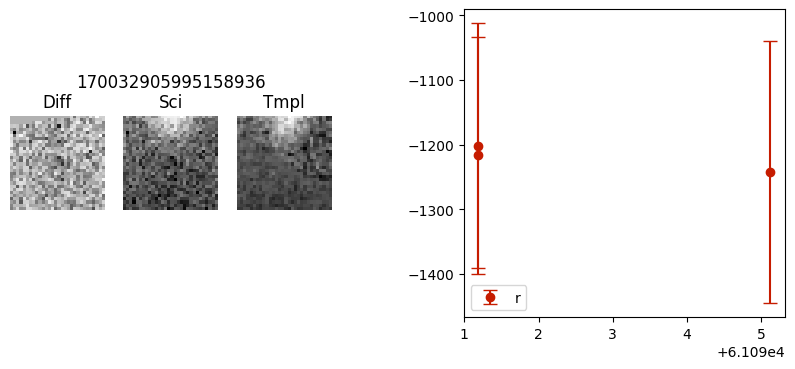

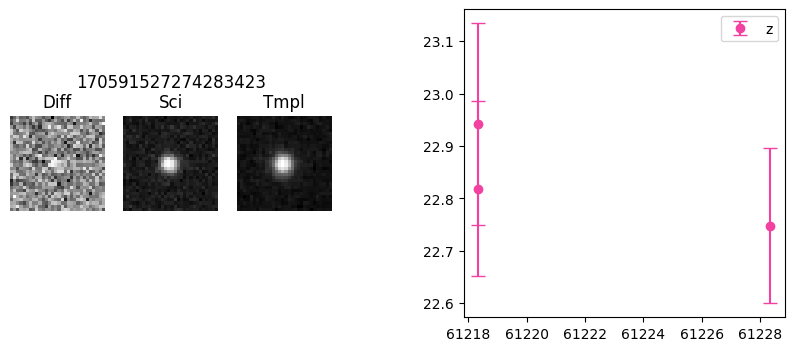

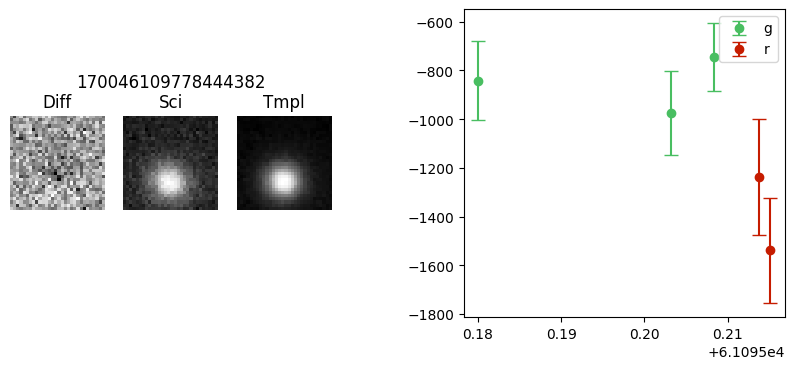

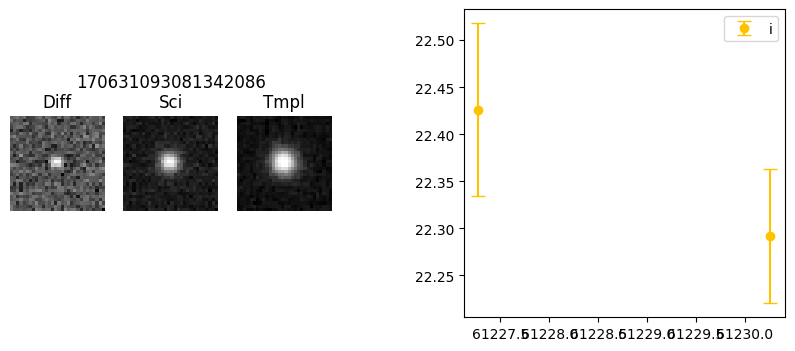

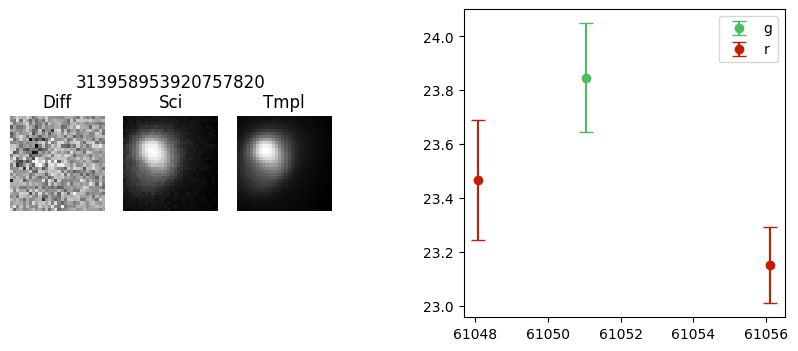

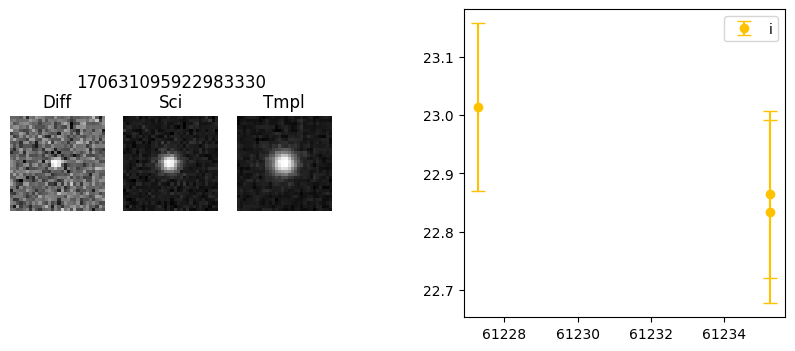

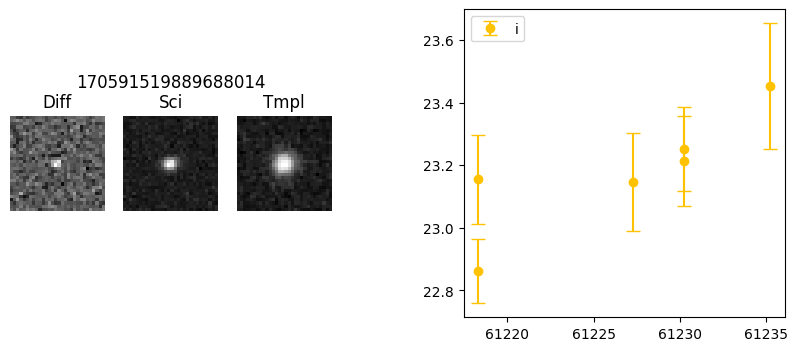

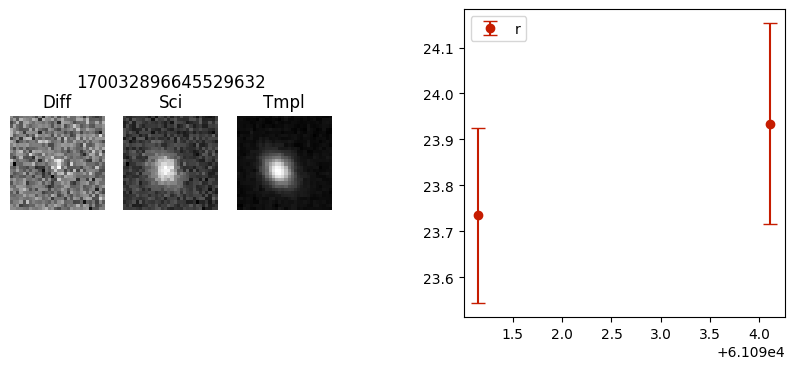

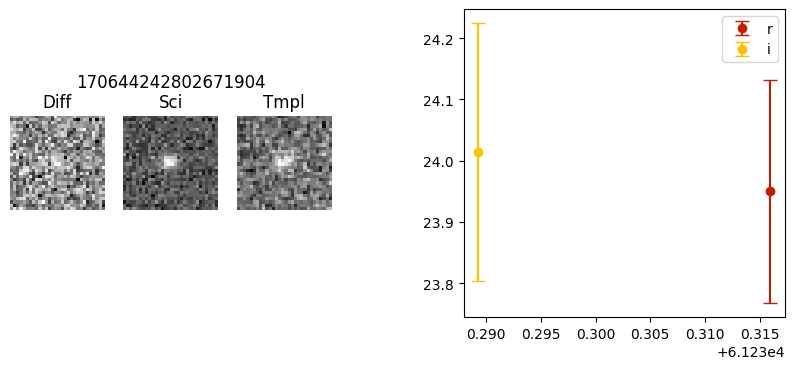

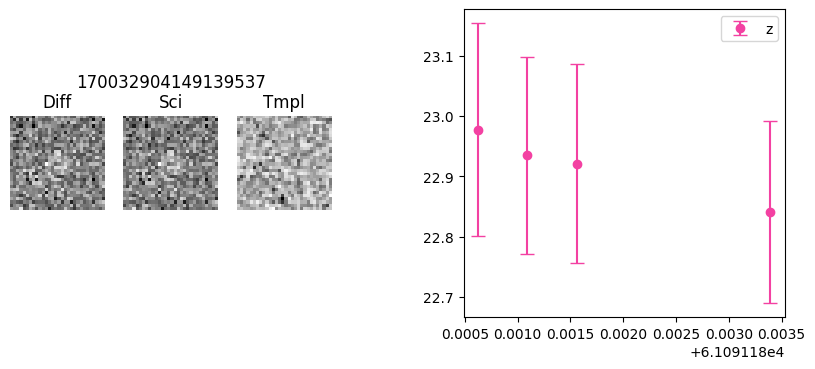

In [ ]:
np.random.seed(9898)
for iyi in np.random.choice(objids_available_bogus, size=10):
  fig, ax = plt.subplot_mosaic('0123444', figsize=(10, 4))
  for ix, n in zip(ax, ['Diff', f'{iyi}\nSci', 'Tmpl']):
    if int(ix) < 3:
      ax[ix].imshow(all_bogus_arrays[iyi][int(ix)], cmap='Greys_r')
      ax[ix].set_title(n)
      ax[ix].axis('off')
    else:
      pass
  ax['3'].axis('off')
  try:
    light_curve_df = all_lc_bogus_arrays[iyi.item()]
    for coloru in filter_colors:

      light_curve_df['r:psfMag'], light_curve_df['r:psfMagErr'] = add_prv_mag(light_curve_df['r:psfFlux'], light_curve_df['r:psfFluxErr'])

      df = light_curve_df[light_curve_df["r:band"] == coloru]
      if len(df) > 0:
        scatt = ax['4'].errorbar(df['r:midpointMjdTai'],df['r:psfMag'], yerr=df['r:psfMagErr'],
                        color=filter_colors[coloru],  fmt='o', capsize=5,
                        label=coloru)

  except Exception as e:
    print(e)
    scatt = ax['4'].scatter(0,0,label='No lc')
  plt.legend()

## Get SN light curves

In [ ]:
file_list_path[3:], zip_paths_lc[1:2]

(['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_stamps_oct_26/sn_zip/file_list_sn_cutouts.pkl'],
 ['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_lc_oct_26/sn.zip'])

In [ ]:
all_lc_sn_arrays = save_lc(file_list_path[3:], zip_paths_lc[1:2])

"There is no item named 'sn/170032913929207826/170032913929207826_lc.csv.gz' in the archive" for 170032913929207826


In [ ]:
objids_available_lcsn= list(all_lc_sn_arrays.keys())

In [ ]:
all_lc_sn_arrays[objids_available_lcsn[0]]

,Unnamed: 0,r:band,r:dec,r:diaSourceId,r:midpointMjdTai,r:psfFlux,r:psfFluxErr,r:ra,r:reliability,r:scienceFlux,r:scienceFluxErr
0,0,r,-49.406232,170050483926335750,61095.083331,-1173.9957,217.87366,63.769861,0.277169,33904.145,214.279140
1,1,i,-49.406344,170028486441828479,61090.054409,-3465.7430,352.85550,63.770064,0.369153,57430.938,350.819150
2,2,g,-49.406477,313897383971258398,61034.161304,732.8759,129.50450,63.769935,0.212357,15087.390,121.325005


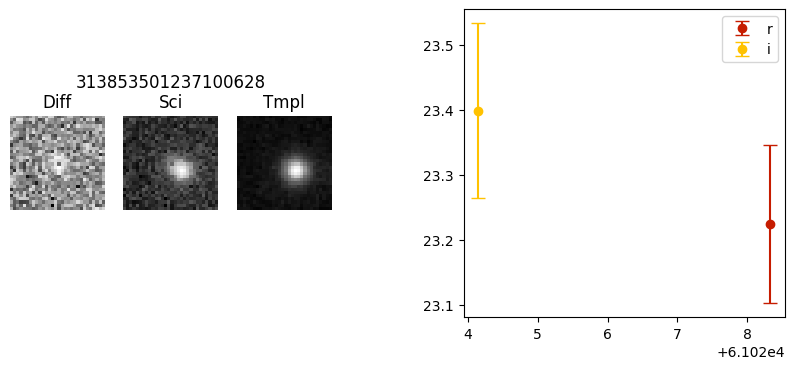

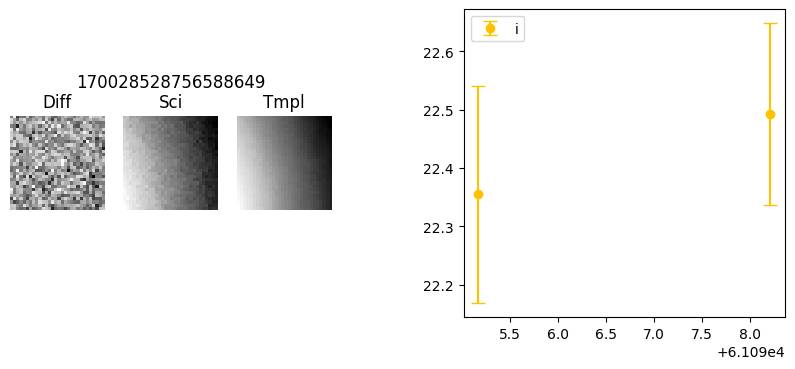

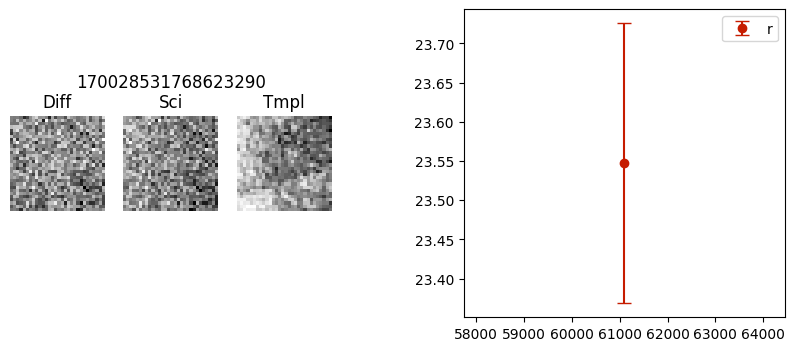

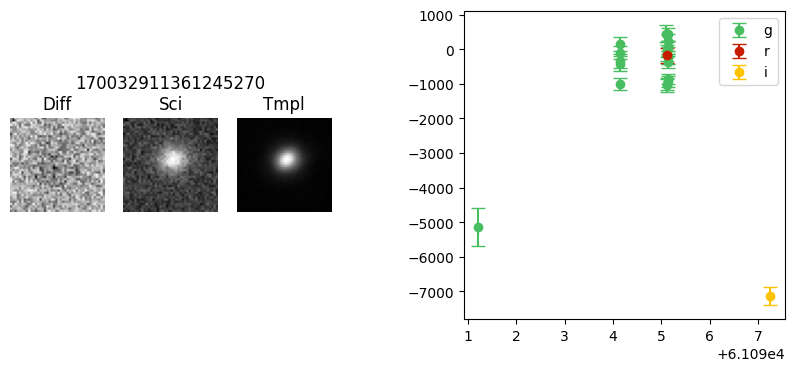

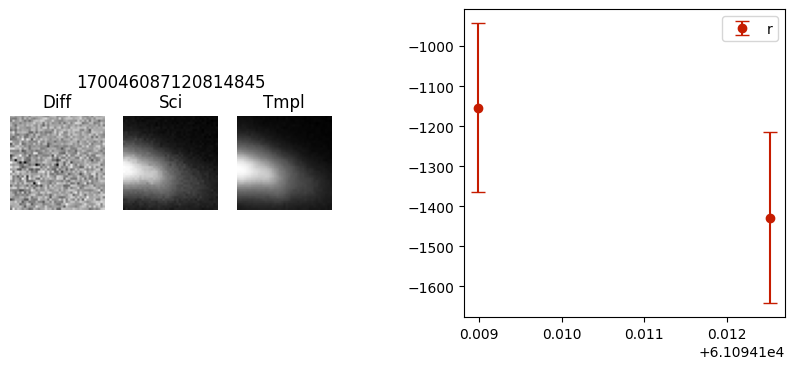

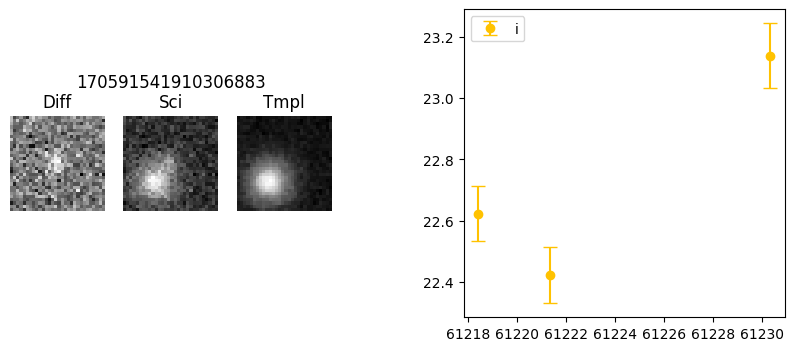

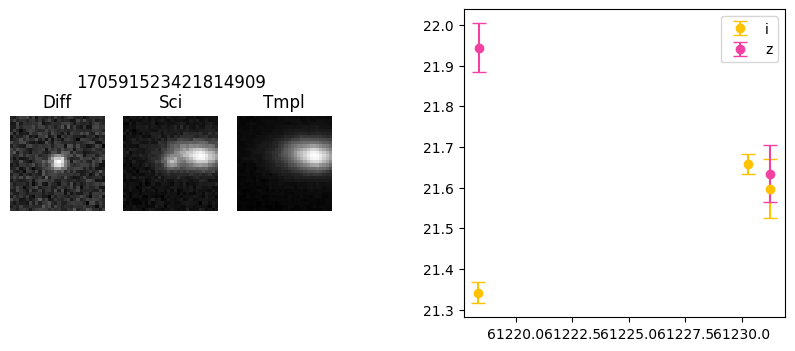

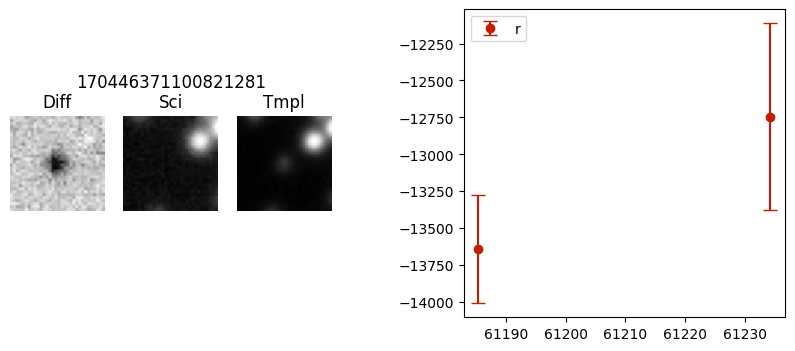

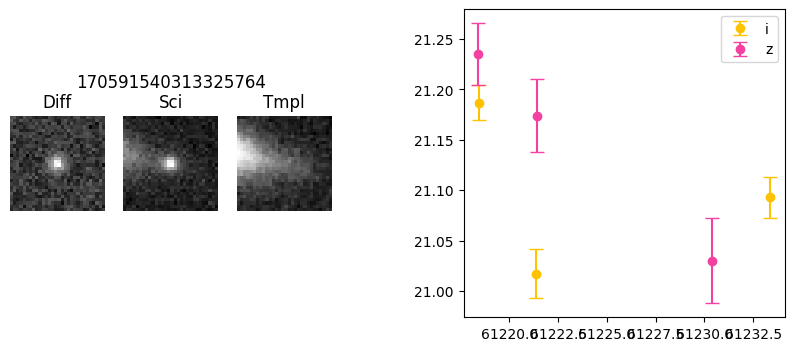

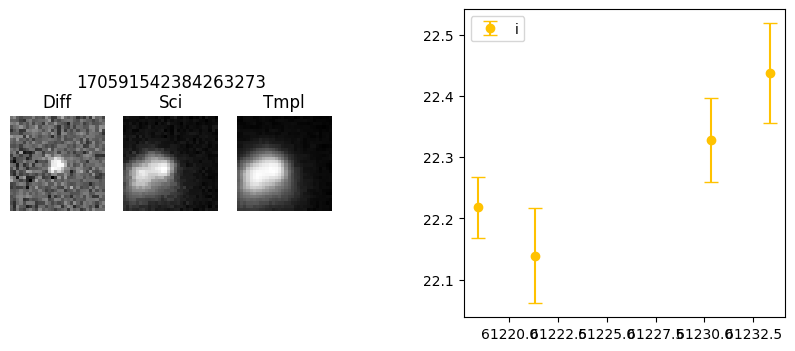

In [ ]:
np.random.seed(565)
for iyi in np.random.choice(objids_available_sn, size=10):
  fig, ax = plt.subplot_mosaic('0123444', figsize=(10, 4))
  for ix, n in zip(ax, ['Diff', f'{iyi}\nSci', 'Tmpl']):
    if int(ix) < 3:
      ax[ix].imshow(all_sn_arrays[iyi][int(ix)], cmap='Greys_r')
      ax[ix].set_title(n)
      ax[ix].axis('off')
    else:
      pass
  ax['3'].axis('off')
  try:
    light_curve_df = all_lc_sn_arrays[iyi.item()]
    for coloru in filter_colors:

      light_curve_df['r:psfMag'], light_curve_df['r:psfMagErr'] = add_prv_mag(light_curve_df['r:psfFlux'], light_curve_df['r:psfFluxErr'])

      df = light_curve_df[light_curve_df["r:band"] == coloru]
      if len(df) > 0:
        scatt = ax['4'].errorbar(df['r:midpointMjdTai'],df['r:psfMag'], yerr=df['r:psfMagErr'],
                        color=filter_colors[coloru],  fmt='o', capsize=5,
                        label=coloru)

  except Exception as e:
    print(e)
    scatt = ax['4'].scatter(0,0,label='No lc')
  plt.legend()

# Get forced light curves

In [ ]:
path_save_fplc = "/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_fp_lc_oct_26"

In [ ]:
zip_paths_fplc = glob.glob(path_save_fplc+'/*zip')
zip_paths_fplc

['/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_fp_lc_oct_26/bogus.zip',
 '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_fp_lc_oct_26/sn.zip',
 '/content/drive/MyDrive/hackathon_colombia_oct_2026/hack_colombia_fp_lc_oct_26/vs.zip']

In [ ]:
def save_fplc(file_list_path, zip_paths_lc):

  all_lc_sn_arrays = dict()
  for pick_path, zip_path in zip(file_list_path, zip_paths_lc):
    type_name = zip_path.split('/')[-1].split('.')[0] # sn/vs/bogus
    with zipfile.ZipFile(zip_path, 'r') as zipper:
      with open(pick_path, 'rb') as file:
        objs_path = pickle.load(file)
        for obj_path in objs_path:
          objid = obj_path[0].split('/')[-2]
          file_name = f"{type_name}/{objid}/{objid}_fp_lc.csv.gz"
          try:

            with zipper.open(file_name, mode='r') as file_stream:
              buffered_stream = io.BufferedReader(file_stream)
              array_data = pd.read_csv(buffered_stream, compression="gzip")
              all_lc_sn_arrays[str(objid)] = array_data
          except Exception as e:
            print(f"{e} for {objid}")

  return all_lc_sn_arrays

## Get vs forced light curves

In [ ]:
all_fplc_vs_arrays = save_fplc(file_list_path[0:1], zip_paths_fplc[-1:])

"There is no item named 'vs/170507920794452012/170507920794452012_fp_lc.csv.gz' in the archive" for 170507920794452012
"There is no item named 'vs/170631094993420692/170631094993420692_fp_lc.csv.gz' in the archive" for 170631094993420692
"There is no item named 'vs/170455187036046534/170455187036046534_fp_lc.csv.gz' in the archive" for 170455187036046534
"There is no item named 'vs/170653037576061702/170653037576061702_fp_lc.csv.gz' in the archive" for 170653037576061702
"There is no item named 'vs/170455190824551216/170455190824551216_fp_lc.csv.gz' in the archive" for 170455190824551216
"There is no item named 'vs/170437564114141462/170437564114141462_fp_lc.csv.gz' in the archive" for 170437564114141462
"There is no item named 'vs/170028490113417233/170028490113417233_fp_lc.csv.gz' in the archive" for 170028490113417233
"There is no item named 'vs/170455188113981823/170455188113981823_fp_lc.csv.gz' in the archive" for 170455188113981823
"There is no item named 'vs/170437563628126621/1

In [ ]:
objids_available_fplcvs = list(all_fplc_vs_arrays.keys())
len(objids_available_fplcvs)

21452

In [ ]:
all_fplc_vs_arrays[objids_available_vs[4]]

,Unnamed: 0,r:band,r:dec,r:diaForcedSourceId,r:midpointMjdTai,r:psfFlux,r:psfFluxErr,r:ra,r:scienceFlux,r:scienceFluxErr
0,0,g,2.945669,170050489985532057,61095.107958,-21838.135000,927.4487,149.947128,1208970.20,915.29694
1,1,i,2.945691,170050489455477004,61095.104637,0.000000,1051.9886,149.947017,1141360.60,1027.14930
2,2,i,2.945691,170050489322307610,61095.104171,0.503682,1061.5818,149.947017,1197759.00,1037.17990
3,3,i,2.945691,170050489185468497,61095.103608,-0.000881,936.3581,149.947017,935510.06,913.87520
4,4,i,2.945691,170050489045483795,61095.103140,0.036157,983.6778,149.947017,1023184.70,959.46466
...,...,...,...,...,...,...,...,...,...,...
117,117,z,2.945738,170032912568680517,61091.215793,13.927748,2745.3210,149.947095,2377869.80,2739.95390
118,118,z,2.945738,170032912458580196,61091.215221,-0.837732,3209.6257,149.947095,2192232.50,3220.64770
119,119,z,2.945738,170032912324886654,61091.214756,1.378893,3101.3300,149.947095,2135133.20,3112.87600
120,120,z,2.945738,170032912168124452,61091.214293,-1.624011,5242.5400,149.947095,2420423.00,5280.62800


'r:psfFlux'
'r:psfFlux'
'r:psfFlux'
'r:psfFlux'
'r:psfFlux'
'r:psfFlux'


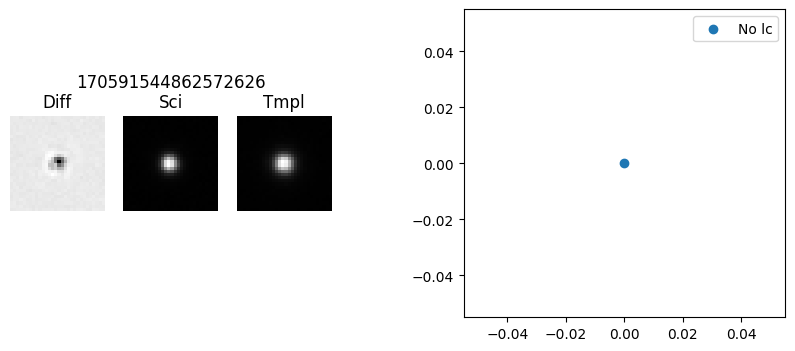

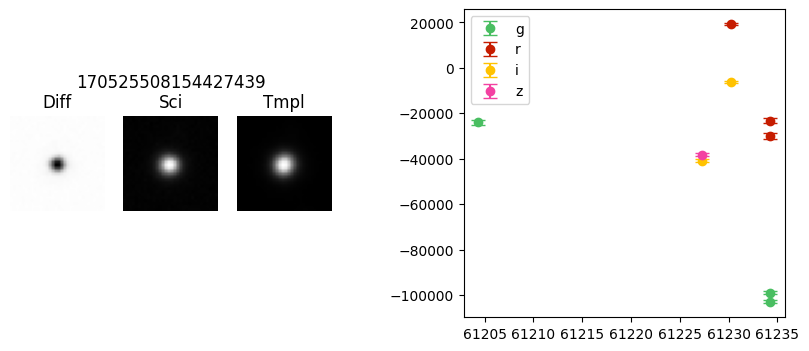

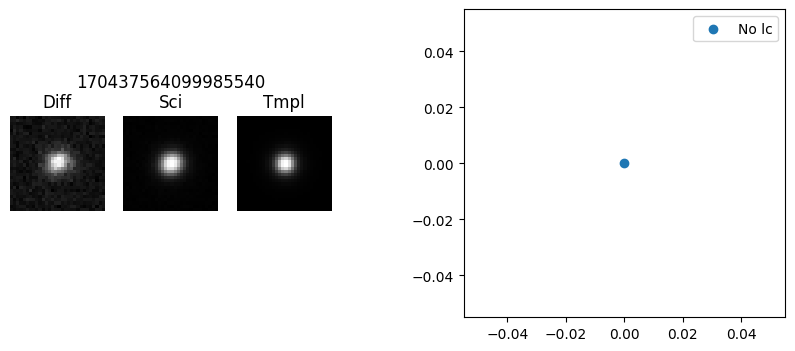

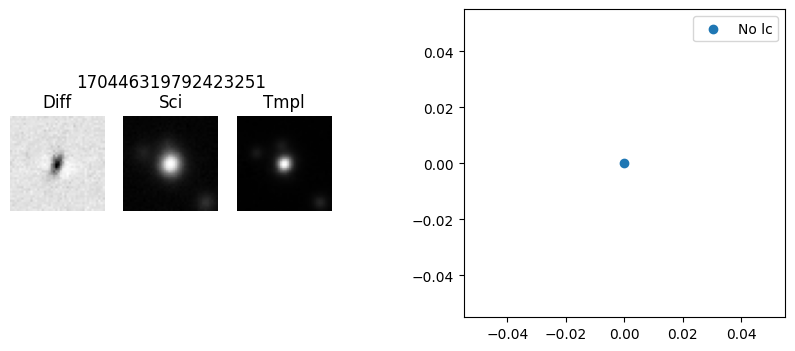

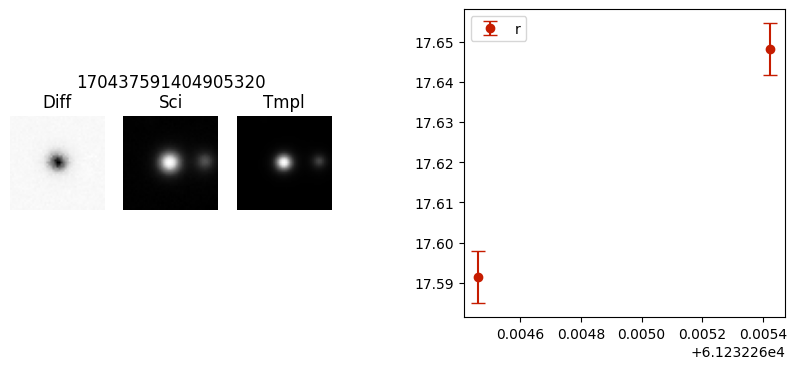

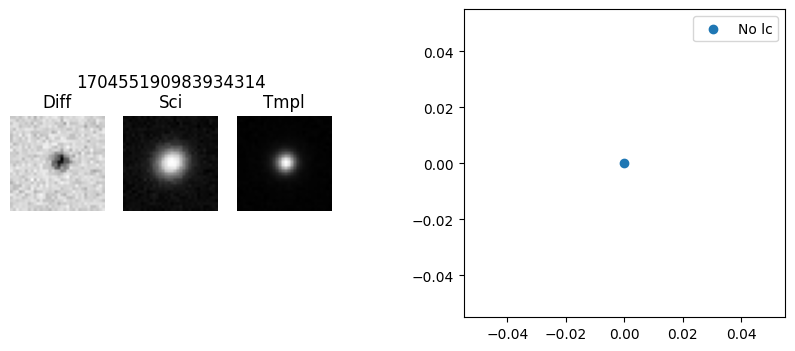

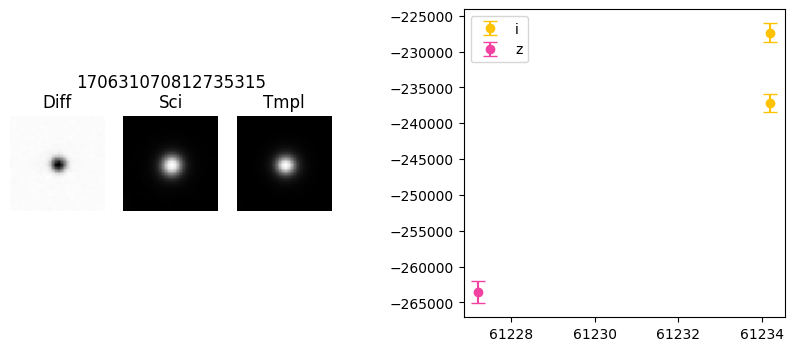

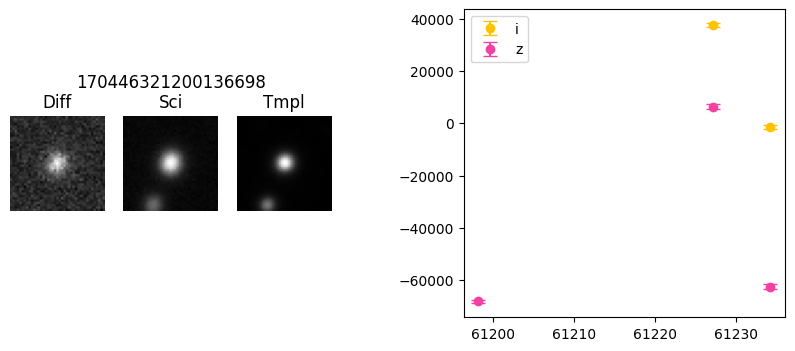

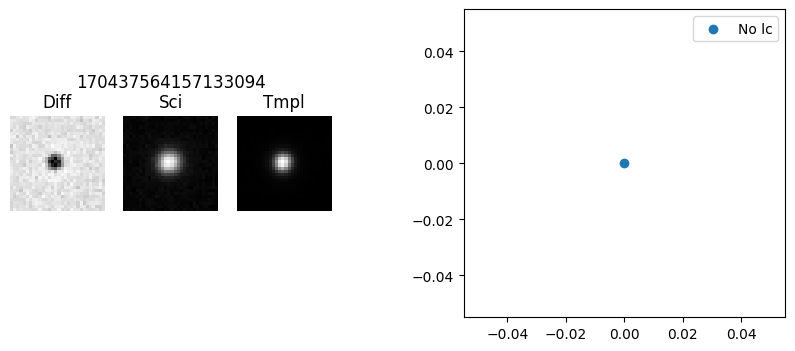

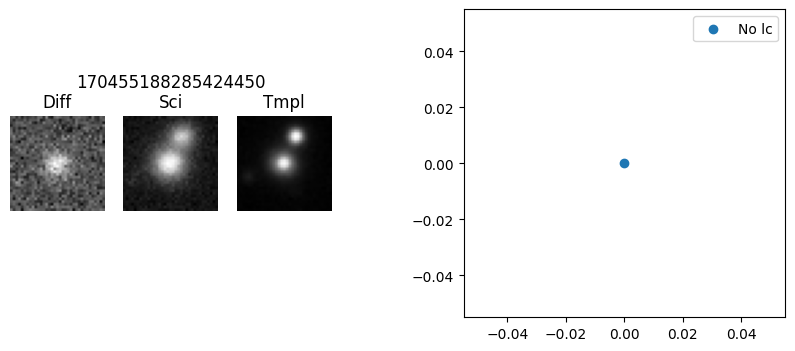

In [ ]:
np.random.seed(565)
for iyi in np.random.choice(objids_available_vs, size=10):
  fig, ax = plt.subplot_mosaic('0123444', figsize=(10, 4))
  for ix, n in zip(ax, ['Diff', f'{iyi}\nSci', 'Tmpl']):
    if int(ix) < 3:
      ax[ix].imshow(all_vs_arrays[iyi][int(ix)], cmap='Greys_r')
      ax[ix].set_title(n)
      ax[ix].axis('off')
    else:
      pass
  ax['3'].axis('off')
  try:
    light_curve_df = all_fplc_vs_arrays[iyi.item()]
    for coloru in filter_colors:

      light_curve_df['r:psfMag'], light_curve_df['r:psfMagErr'] = add_prv_mag(light_curve_df['r:psfFlux'], light_curve_df['r:psfFluxErr'])

      df = light_curve_df[light_curve_df["r:band"] == coloru]
      if len(df) > 0:
        scatt = ax['4'].errorbar(df['r:midpointMjdTai'],df['r:psfMag'], yerr=df['r:psfMagErr'],
                        color=filter_colors[coloru],  fmt='o', capsize=5,
                        label=coloru)

  except Exception as e:
    print(e)
    scatt = ax['4'].scatter(0,0,label='No lc')
  plt.legend()

## Same for bogus and SN